In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [2]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable GPU in Runtime settings.")

PyTorch Version: 2.14.1+cpu
CUDA Available: False
GPU not available. Enable GPU in Runtime settings.


In [3]:
!pip install -q ultralytics fastapi uvicorn python-multipart opencv-python-headless nest-asyncio pyngrok

In [4]:
from IPython.display import display, HTML
from google.colab import output

proxy_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

display(HTML(
    f'<a href="{proxy_url}/docs" target="_blank">'
    'Open VisionPort API Documentation</a>'
))

In [5]:
from ultralytics import YOLO
import torch

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

# Use GPU if available
device = 0 if torch.cuda.is_available() else "cpu"

print("VisionPort model loaded successfully!")
print("Running device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort model loaded successfully!
Running device: cpu


In [10]:
from google.colab import files

uploaded = files.upload()

print("Uploaded images:", list(uploaded.keys()))

Saving download.jpg to download.jpg
Uploaded images: ['download.jpg']



Image: download.jpg
Object counts: {}
Total objects: 0


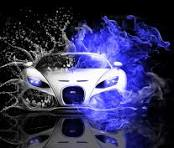

In [11]:
import cv2
from google.colab.patches import cv2_imshow
import os

os.makedirs("/content/visionport_output", exist_ok=True)

for image_name in uploaded.keys():

    image = cv2.imread(image_name)

    if image is None:
        print("Invalid image:", image_name)
        continue

    # Run YOLO inference on GPU
    results = model.predict(
        source=image,
        device=device,
        conf=0.40,
        verbose=False
    )

    counts = {}

    for result in results:

        for box in result.boxes:

            class_id = int(box.cls[0])
            label = model.names[class_id]
            confidence = float(box.conf[0])

            # Keep only traffic-related classes
            if label not in [
                "person", "bicycle", "car",
                "motorcycle", "bus", "truck"
            ]:
                continue

            counts[label] = counts.get(label, 0) + 1

    # Create annotated image
    annotated_image = results[0].plot()

    print("\nImage:", image_name)
    print("Object counts:", counts)
    print("Total objects:", sum(counts.values()))

    # Save image
    output_path = "/content/visionport_output/" + image_name
    cv2.imwrite(output_path, annotated_image)

    # Display result
    cv2_imshow(annotated_image)

In [12]:
from fastapi import FastAPI, UploadFile, File, HTTPException
import numpy as np
import cv2
import torch

app = FastAPI(
    title="VisionPort Traffic Detection",
    description="Traffic object detection using YOLO and GPU",
    version="1.0"
)

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLOv8 Nano"
    }

@app.get("/health")
def health():
    return {
        "api": "Active",
        "gpu_available": torch.cuda.is_available()
    }

@app.post("/detect")
async def detect_traffic(file: UploadFile = File(...)):

    contents = await file.read()

    image_array = np.frombuffer(contents, dtype=np.uint8)
    image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    if image is None:
        raise HTTPException(status_code=400, detail="Invalid image")

    results = model.predict(
        source=image,
        device=device,
        conf=0.40,
        verbose=False
    )

    detections = []
    counts = {}

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        label = model.names[class_id]
        confidence = float(box.conf[0])

        if label not in ["person", "bicycle", "car", "motorcycle", "bus", "truck"]:
            continue

        coordinates = box.xyxy[0].cpu().tolist()

        counts[label] = counts.get(label, 0) + 1

        detections.append({
            "class": label,
            "confidence": round(confidence, 3),
            "bounding_box": coordinates
        })

    return {
        "project": "VisionPort",
        "filename": file.filename,
        "total_objects": len(detections),
        "object_counts": counts,
        "detections": detections
    }

print("FastAPI application created successfully!")

FastAPI application created successfully!


In [13]:
import threading
import time
import uvicorn
import nest_asyncio

nest_asyncio.apply()

def start_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="warning"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

time.sleep(3)

print("VisionPort API server started!")

VisionPort API server started!


In [14]:
from IPython.display import display, HTML
from google.colab import output

proxy_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

display(HTML(
    f'<a href="{proxy_url}/docs" target="_blank">'
    'Open VisionPort API Documentation</a>'
))